# Mission 3 — Control test: data analytics (draft)

Goal, plan and objectives: [../index.md](../index.md). The test was run by
[../src/control_test.py](../src/control_test.py), which wrote two files into `../data`:

- `test_<stamp>.jsonl` — the timed log of the test (commands sent, confirmations, takeovers, RC tests);
- `mqtt_<stamp>.jsonl` — every MQTT message: the boat's telemetry once a second, and the commands.

This notebook goes through the five objectives one by one. Each section has the numbers, a chart
where the eye is better than a number, and an **Operator** note with what the person running the
test said about it (their comments are at the very end, as written). The last section collects the
verdicts and the follow-up questions.

Positions are shown as metres from where the boat was when the test started. No absolute
coordinates are displayed or stored in this notebook's outputs.

The Body Control Unit is the board that drives the motor and rudder and switches between RC and
autonomous control (a Raspberry Pi Pico); the main controller is the Seeed XIAO ESP32-S3.

In [1]:
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Circle, Patch

DATA_DIR = Path("../data")
STAMP = None  # the part of the log file names after "test_"; None = the latest test in ../data

# As in ../src/control_test.py (not written to the log):
TAKEOVER_AT = (0.25, 0.5, 0.75, 0.35)  # when in a run a takeover is asked for, fraction of the run
RC_TEST_S = 360  # what an RC test between sections was assumed to take

# As in the boat's gnc.py:
ARRIVAL_RADIUS_M = 4
STILL_MOVING_M_S = 0.15  # _stop() brakes above this speed
KN_TO_M_S = 0.514444
EARTH_RADIUS_M = 6371000

# Chart style: three categorical colours (checked for colour-blind separation), quiet chrome.
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
RUN_WASH, RC_WASH = "#dbe9fb", "#fbe3d8"  # background bands: destination active / Body Control Unit in RC mode
TIME_RAMP = LinearSegmentedColormap.from_list("time", ["#cde2fb", "#3987e5", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": AXIS, "axes.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-", "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "lines.linewidth": 2, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "figure.dpi": 110,
})
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", None)

## Loading

The telemetry is flattened into one row per message (`tel`), with time in minutes from the start of
the test. Positions become metres east / north of the start position, and the coordinate columns
are dropped. `runs` are the eight destination-to-stop windows, `rc_windows` the stretches where the
Body Control Unit reported RC mode, and `interventions` the takeovers and RC tests as the operator confirmed them.

In [2]:
test_path = sorted(DATA_DIR.glob("test_%s.jsonl" % (STAMP or "*")))[-1]
mqtt_path = test_path.with_name(test_path.name.replace("test_", "mqtt_"))
print("test log:", test_path.name, "| mqtt log:", mqtt_path.name)

ev = pd.DataFrame([json.loads(line) for line in open(test_path)])
raw = [json.loads(line) for line in open(mqtt_path)]

start = ev.loc[ev.event == "test_started"].iloc[0]
T0 = start.unix
ev["min"] = (ev.unix - T0) / 60
END_MIN = ev.loc[ev.event.isin(["test_finished", "test_aborted"]), "min"].iloc[-1]

tel = pd.json_normalize([dict(unix=r["unix"], **r["data"]) for r in raw if r.get("topic", "").endswith("/telemetry")])
tel["min"] = (tel.unix - T0) / 60
commands = pd.DataFrame([{"min": (r["unix"] - T0) / 60, "cmd": r["data"].get("cmd")}
                         for r in raw if r.get("topic", "").endswith("/cmd")])
recorder_events = pd.DataFrame([{"min": (r["unix"] - T0) / 60, "event": r["event"]} for r in raw if "event" in r])

# Positions -> metres from the start position (equirectangular, as in mission 2), coordinates dropped.
M_PER_E7 = EARTH_RADIUS_M * math.pi / 180 / 1e7
cos_lat = math.cos(math.radians(start.start_lat_e7 / 1e7))
tel["east_m"] = (tel["gps.lon_e7"] - start.start_lon_e7) * M_PER_E7 * cos_lat
tel["north_m"] = (tel["gps.lat_e7"] - start.start_lat_e7) * M_PER_E7
tel["dest_east_m"] = (tel["destination.lon_e7"] - start.start_lon_e7) * M_PER_E7 * cos_lat
tel["dest_north_m"] = (tel["destination.lat_e7"] - start.start_lat_e7) * M_PER_E7
tel = tel.drop(columns=[c for c in tel.columns if c.endswith("lat_e7") or c.endswith("lon_e7")])
ev = ev.drop(columns=[c for c in ev.columns if c.endswith("lat_e7") or c.endswith("lon_e7")])

# The Body Control Unit's status is missing from a message when the main controller's read of it failed its checksum.
tel["pico_ok"] = tel["bcu.heartbeat"].notna()
tel["mode"] = tel["bcu.esp32_mode"].map({True: "autonomous", False: "rc"}).ffill()
tel["navigating"] = tel["output.reason"] == "navigating"
tel["cmd_throttle_us"] = 1500 + 5 * tel["output.throttle"]  # what the main controller's command means to the Body Control Unit
tel["cmd_rudder_us"] = 1500 + 5 * tel["output.rudder"]
in_test = tel[(tel["min"] >= 0) & (tel["min"] <= END_MIN)]

# The eight runs: destination sent -> stop sent.
sent = ev[ev.event == "destination_sent"].set_index("number")
stopped = ev[ev.event == "stop_sent"].set_index("number")
runs = pd.DataFrame({"section": sent.section.astype(int), "direction": sent.direction,
                     "start_min": sent["min"], "stop_min": stopped["min"]})
runs.index = runs.index.astype(int).rename("run")
runs["takeover"] = [n in set(ev.loc[ev.event == "takeover_requested", "destination"]) for n in runs.index]

# Stretches where the Body Control Unit reported RC mode.
is_rc = (tel["mode"] == "rc").to_numpy()
edges = np.flatnonzero(np.diff(np.r_[False, is_rc, False].astype(int)))
rc_windows = pd.DataFrame({"start_min": tel["min"].to_numpy()[edges[0::2]],
                           "end_min": tel["min"].to_numpy()[np.minimum(edges[1::2], len(tel) - 1)]})
rc_windows = rc_windows[rc_windows.end_min > 0].reset_index(drop=True)


def shade(ax, runs_too=True):
    """Background bands on a time axis (minutes): destination active, Body Control Unit in RC mode."""
    if runs_too:
        for r in runs.itertuples():
            ax.axvspan(r.start_min, r.stop_min, color=RUN_WASH, lw=0, zorder=0)
    for w in rc_windows.itertuples():
        ax.axvspan(w.start_min, w.end_min, color=RC_WASH, lw=0, zorder=0.1)


BAND_KEYS = [Patch(color=RUN_WASH, label="destination active"), Patch(color=RC_WASH, label="Body Control Unit in RC mode")]


def time_axis(ax):
    ax.set_xlim(-1, END_MIN + 0.5)
    ax.set_xlabel("minutes from the start of the test")


# What the operator did to the boat during the test (from the operator's comments at the end;
# the minutes are where the data shows it: a dip in signal strength, a swing of the heading).
OPERATOR_ACTIONS = [(13.5, "access point repositioned"), (33.15, "boat rotated by hand")]


def mark_operator(ax, labels=True):
    for minute, what in OPERATOR_ACTIONS:
        ax.axvline(minute, color=INK_2, lw=1)
        if labels:
            ax.annotate(what, (minute, 1), xycoords=("data", "axes fraction"), xytext=(4, -4),
                        textcoords="offset points", va="top", color=INK_2, fontsize=9)


print("test: %.1f min, %d telemetry messages, %d commands, %d log events" % (END_MIN, len(in_test), len(commands), len(ev)))
print("parameters:", {k: (start[k] if isinstance(start[k], (bool, np.bool_)) else int(start[k]))
                      for k in ("sections", "cycles", "cycle_s", "run_s", "offset_m", "takeover_every", "dry_run")})

test log: test_104325.jsonl | mqtt log: mqtt_104325.jsonl


test: 42.2 min, 2535 telemetry messages, 16 commands, 96 log events
parameters: {'sections': 4, 'cycles': 2, 'cycle_s': 300, 'run_s': 60, 'offset_m': 50, 'takeover_every': 2, 'dry_run': False}


## 1. Planned and performed

The plan was about an hour: four autonomous sections of two 5-minute cycles, a takeover in every
second run, and an RC test of about 6 minutes between sections. The chart puts that next to what
happened, on one time axis.

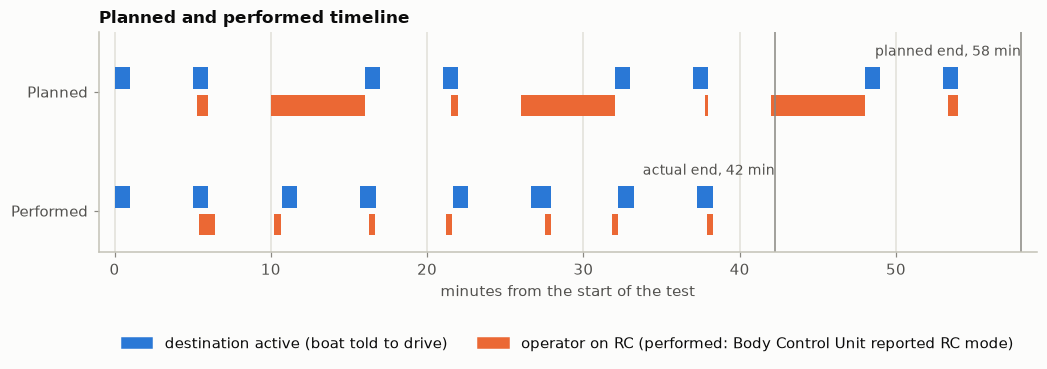

,planned,performed
duration,58 min,42.2 min
destinations sent,8,8
time with a destination,8 min,8.4 min
takeovers during a run,4,4
RC tests between sections,3,3
RC test length,~6 min each,24 s each on average


In [3]:
cycle_min, run_min = start.cycle_s / 60, start.run_s / 60
planned_runs, planned_rc, at, number = [], [], 0.0, 0
for section in range(1, int(start.sections) + 1):
    for cycle in range(int(start.cycles)):
        number += 1
        planned_runs.append((at, run_min))
        if start.takeover_every and number % start.takeover_every == 0:
            frac = TAKEOVER_AT[(number // int(start.takeover_every) - 1) % len(TAKEOVER_AT)]
            planned_rc.append((at + frac * run_min, run_min * (1 - frac)))  # until the run's stop, at the latest
        at += cycle_min
    if section < start.sections:
        planned_rc.append((at, RC_TEST_S / 60))
        at += RC_TEST_S / 60
planned_end = at

fig, ax = plt.subplots(figsize=(11, 2.6))
rows = [("planned", 3), ("performed", 2)]
ax.broken_barh(planned_runs, (3.05, 0.36), color=BLUE, lw=0)
ax.broken_barh(planned_rc, (2.59, 0.36), color=ORANGE, lw=0)
ax.broken_barh([(r.start_min, r.stop_min - r.start_min) for r in runs.itertuples()], (1.05, 0.36), color=BLUE, lw=0)
ax.broken_barh([(w.start_min, w.end_min - w.start_min) for w in rc_windows.itertuples()], (0.59, 0.36), color=ORANGE, lw=0)
for x, label in ((planned_end, "planned end %.0f min" % planned_end), (END_MIN, "end %.0f min" % END_MIN)):
    ax.axvline(x, color=MUTED, lw=1)
ax.text(planned_end, 3.55, "planned end, %.0f min" % planned_end, ha="right", va="bottom", color=INK_2, fontsize=9)
ax.text(END_MIN, 1.55, "actual end, %.0f min" % END_MIN, ha="right", va="bottom", color=INK_2, fontsize=9)
ax.set_yticks([3, 1], ["Planned", "Performed"])
ax.set_ylim(0.3, 4.0)
ax.grid(axis="y", visible=False)
ax.set_xlim(-1, planned_end + 1)
ax.set_xlabel("minutes from the start of the test")
ax.set_title("Planned and performed timeline")
ax.legend(handles=[Patch(color=BLUE, label="destination active (boat told to drive)"),
                   Patch(color=ORANGE, label="operator on RC (performed: Body Control Unit reported RC mode)")],
          loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2)
plt.show()

rc_total = (rc_windows.end_min - rc_windows.start_min).sum()
pd.DataFrame({
    "planned": ["%.0f min" % planned_end, len(planned_runs), "%.0f min" % (len(planned_runs) * run_min),
                sum(1 for n in range(1, len(planned_runs) + 1) if start.takeover_every and n % start.takeover_every == 0),
                int(start.sections) - 1, "~%.0f min each" % (RC_TEST_S / 60)],
    "performed": ["%.1f min" % END_MIN, len(runs), "%.1f min" % (runs.stop_min - runs.start_min).sum(),
                  int((ev.event == "takeover_finished").sum()), int((ev.event == "rc_test_finished").sum()),
                  "%.0f s each on average" % ev.loc[ev.event == "rc_test_finished", "duration_s"].mean()],
}, index=["duration", "destinations sent", "time with a destination", "takeovers during a run",
          "RC tests between sections", "RC test length"])

**What this shows.** All eight destinations, four takeovers and three RC tests were done, in the
planned order. The test is shorter than planned only because the RC tests between sections took
well under a minute each instead of the six assumed. Every 5-minute cycle ran its full length.

> **Operator:** the RC checks were meant to be short.

## 2. Telemetry reliability (objective 3)

The boat numbers its telemetry messages (`seq`), so a lost message is a hole in the numbering, and
a late one shows as a long wait between two arrivals. The boat sends one message a second.

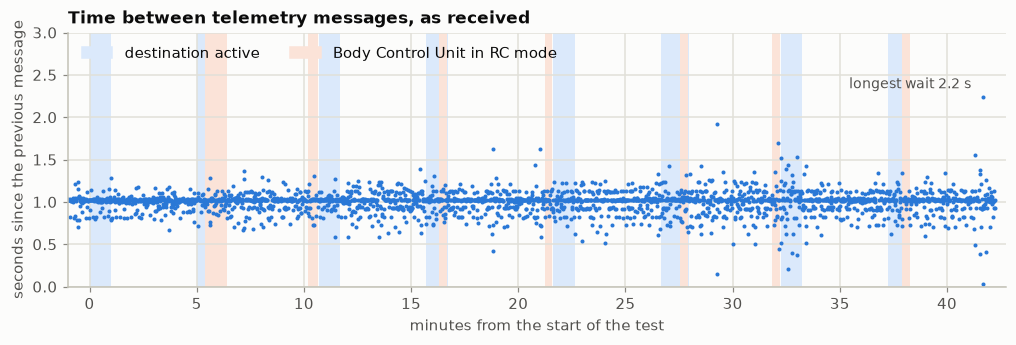

,telemetry
messages the boat numbered in this period,2597
messages received,2597
messages lost,0
out of order or repeated,0
median wait between messages,1.02 s
99th percentile wait,1.32 s
longest wait,2.23 s
waits over 2 s,1
waits over 5 s,0
messages the boat dropped before sending,0


In [4]:
seq_step = tel["seq"].diff().dropna()
lost = int((seq_step[seq_step > 1] - 1).sum())
gap = tel.unix.diff()
link_first, link_last = tel.iloc[0], tel.iloc[-1]

fig, ax = plt.subplots(figsize=(11, 3))
shade(ax)
ax.scatter(tel["min"], gap, s=7, color=BLUE, linewidths=0)
worst = gap.idxmax()
ax.annotate("longest wait %.1f s" % gap[worst], (tel["min"][worst], gap[worst]), xytext=(-8, 6),
            textcoords="offset points", ha="right", color=INK_2, fontsize=9)
ax.set_ylim(0, max(3, gap.max() * 1.15))
ax.set_ylabel("seconds since the previous message")
ax.set_title("Time between telemetry messages, as received")
ax.legend(handles=BAND_KEYS, loc="upper left", ncol=2)
time_axis(ax)
plt.show()

pd.Series({
    "messages the boat numbered in this period": "%d" % (tel.seq.iloc[-1] - tel.seq.iloc[0] + 1),
    "messages received": "%d" % len(tel),
    "messages lost": "%d" % lost,
    "out of order or repeated": "%d" % (seq_step < 1).sum(),
    "median wait between messages": "%.2f s" % gap.median(),
    "99th percentile wait": "%.2f s" % gap.quantile(0.99),
    "longest wait": "%.2f s" % gap.max(),
    "waits over 2 s": "%d" % (gap > 2).sum(),
    "waits over 5 s": "%d" % (gap > 5).sum(),
    "messages the boat dropped before sending": "%d" % (link_last["link.dropped_telemetry"] - link_first["link.dropped_telemetry"]),
    "logger's own disconnects during the test": "%d" % ((recorder_events.event == "disconnected") & (recorder_events["min"] < END_MIN)).sum(),
}, name="telemetry").to_frame()

**What this shows.** Every message the boat sent arrived, in order. The dots sit on the 1-second
line with ordinary network jitter; the longest wait is a little over two seconds and is a late
message, not a lost one.

**Where the eye helps.** A table can say "no losses"; the chart also shows there is no pattern in
the jitter: it does not get worse while a destination is active or while the Body Control Unit is in RC mode.

## 3. Internet access point (objective 5)

The boat reports how often its WiFi and broker connections came up, how many link errors it had,
and its WiFi signal strength. If the access point had dropped, the connect counts would have gone up.

The access point is carried on the boat itself, so the WiFi hop is a few centimetres long and stays
that way on the water. What can vary with distance from shore is the access point's own connection
to the internet, which the boat does not measure.

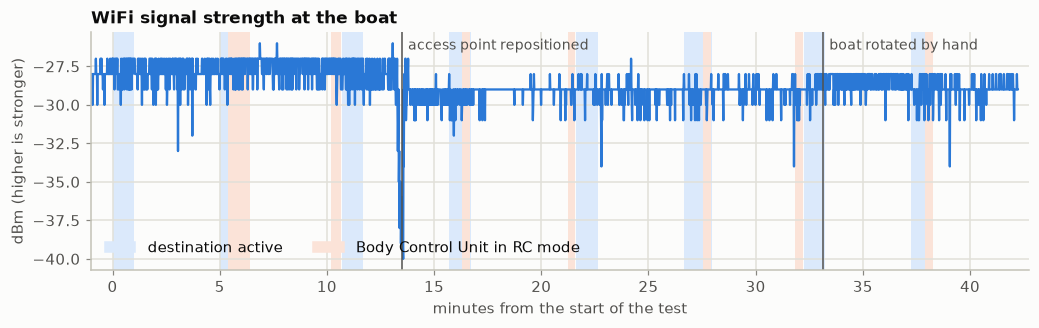

,at the first message,at the last message
WiFi connects since boot,1,1
broker connects since boot,1,1
link errors,0,0
telemetry messages sent,650,3246
commands received,0,16
signal (dBm),-28,-29


In [5]:
fig, ax = plt.subplots(figsize=(11, 2.8))
shade(ax)
ax.plot(tel["min"], tel["link.rssi"], color=BLUE, lw=1.5)
mark_operator(ax)
ax.set_ylabel("dBm (higher is stronger)")
ax.set_title("WiFi signal strength at the boat")
ax.legend(handles=BAND_KEYS, loc="lower left", ncol=2)
time_axis(ax)
plt.show()

pd.DataFrame({
    "at the first message": [link_first["link.wifi_connects"], link_first["link.mqtt_connects"], link_first["link.errors"],
                             link_first["link.tx"], link_first["link.rx"], link_first["link.rssi"]],
    "at the last message": [link_last["link.wifi_connects"], link_last["link.mqtt_connects"], link_last["link.errors"],
                            link_last["link.tx"], link_last["link.rx"], link_last["link.rssi"]],
}, index=["WiFi connects since boot", "broker connects since boot", "link errors", "telemetry messages sent",
          "commands received", "signal (dBm)"]).astype(int)

**What this shows.** One WiFi connect and one broker connect for the whole test, no link errors:
the access point stayed up and the boat never had to reconnect. All 16 commands arrived.

The signal is very strong and flat, as expected with the access point on board. The one dip, at
about minute 13.5, is the operator repositioning it; the level settles about 1 dB lower afterwards.

Since every telemetry message also arrived (section 2), the access point's internet connection held
for the whole test too, at this location.

> **Operator:** the access point is integrated in the boat. It was checked and repositioned around
> minute 14.

## 4. Electronics (objective 1)

Everything the boat counts about its own health, at the start and the end of the recording: resets,
task errors, the I2C link to the Body Control Unit, compass and GPS recoveries, memory, battery.

In [6]:
first, last = tel.iloc[0], tel.iloc[-1]
pico = tel[tel.pico_ok]
pico_cmd_errors = (pico["bcu.cmd_errors"].diff() % 256).fillna(0)  # an 8-bit counter on the Body Control Unit: it wraps
task_names = sorted({c.split(".")[1] for c in tel.columns if c.startswith("tasks.")})

health = pd.DataFrame({
    "start": [first.uptime_s, first.reset_cause,
              sum(first["tasks.%s.errors" % n] for n in task_names), first.i2c_recoveries,
              first["bcu_errors.write"], first["bcu_errors.status_i2c"], first["bcu_errors.status_checksum"], 0,
              first["compass.inits"], first["compass.report_restarts"], first["gps.recoveries"], first["gps.checksum_errors"],
              pico["bcu.overruns"].iloc[0], False, first["memory.heap_free"] // 1024],
    "end": [last.uptime_s, last.reset_cause,
            sum(last["tasks.%s.errors" % n] for n in task_names), last.i2c_recoveries,
            last["bcu_errors.write"], last["bcu_errors.status_i2c"], last["bcu_errors.status_checksum"], int(pico_cmd_errors.sum()),
            last["compass.inits"], last["compass.report_restarts"], last["gps.recoveries"], last["gps.checksum_errors"],
            pico["bcu.overruns"].iloc[-1], bool((pico["bcu.wdt_reset"] == True).any()), last["memory.heap_free"] // 1024],
}, index=["main controller uptime (s)", "main controller reset cause", "task errors (all tasks)", "I2C bus recoveries",
          "commands to the Body Control Unit that failed to send", "Body Control Unit status reads: I2C error", "Body Control Unit status reads: bad checksum",
          "commands the Body Control Unit rejected (bad checksum), during the recording",
          "compass initialisations", "compass report restarts", "GPS module recoveries", "GPS sentence checksum errors",
          "Body Control Unit loop overruns", "Body Control Unit restarted by its watchdog", "main controller free heap (KB)"])
health["change"] = [e - s if isinstance(s, (int, float, np.integer, np.floating)) and not isinstance(s, bool) else "" for s, e in zip(health.start, health.end)]
uptime_ok = (tel.uptime_s.diff().dropna() == 1).all()
print("uptime counts up by 1 every message (no restart):", uptime_ok)
health

uptime counts up by 1 every message (no restart): True


,start,end,change
main controller uptime (s),656,3252,2596
main controller reset cause,power-on,power-on,
task errors (all tasks),0,0,0
I2C bus recoveries,0,0,0
commands to the Body Control Unit that failed to send,1,1,0
Body Control Unit status reads: I2C error,1,1,0
Body Control Unit status reads: bad checksum,34,197,163
"commands the Body Control Unit rejected (bad checksum), during the recording",0,363,363
compass initialisations,1,1,0
compass report restarts,0,0,0


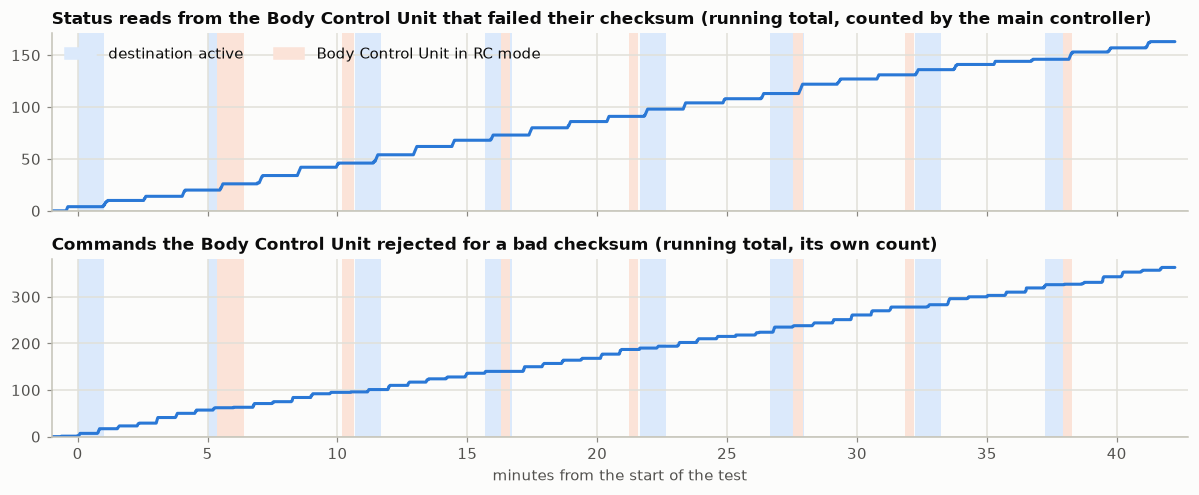

failed status reads come in 29 bursts of about 6, one every 89 s (between 85 and 94 s apart)
rejected commands come in 56 bursts of about 6, one every 45 s (between 38 and 89 s apart)
commands sent to the Body Control Unit during the recording: 51920; rejected by it: 363 (0.70%)


,status reads,failed checksum,failed %
whole recording,2597,163,6.3
while navigating,500,47,9.4
while idle,2097,116,5.5


In [7]:
status_bad = tel["bcu_errors.status_checksum"].diff().fillna(0)

fig, axes = plt.subplots(2, 1, figsize=(11, 4.6), sharex=True)
for ax, x, y, title in (
        (axes[0], tel["min"], status_bad.cumsum(), "Status reads from the Body Control Unit that failed their checksum (running total, counted by the main controller)"),
        (axes[1], pico["min"], pico_cmd_errors.cumsum(), "Commands the Body Control Unit rejected for a bad checksum (running total, its own count)")):
    shade(ax)
    ax.plot(x, y, color=BLUE)
    ax.set_ylim(0, None)
    ax.set_title(title)
axes[0].legend(handles=BAND_KEYS, loc="upper left", ncol=2)
time_axis(axes[1])
fig.tight_layout()
plt.show()

def bursts(minutes, quiet_s):
    # Start times (min) of the groups of errors separated by more than quiet_s without one.
    minutes = np.asarray(minutes)
    return minutes[np.r_[True, np.diff(minutes) > quiet_s / 60]]


status_bursts = bursts(tel["min"][status_bad > 0], 20)
command_bursts = bursts(pico["min"][pico_cmd_errors > 0], 10)
for name, starts, total in (("failed status reads", status_bursts, status_bad.sum()), ("rejected commands", command_bursts, pico_cmd_errors.sum())):
    spacing = np.diff(starts) * 60
    print("%s come in %d bursts of about %.0f, one every %.0f s (between %.0f and %.0f s apart)" % (
        name, len(starts), total / len(starts), np.median(spacing), spacing.min(), spacing.max()))

per_state = pd.DataFrame({
    "status reads": [len(tel), tel.navigating.sum(), (~tel.navigating).sum()],
    "failed checksum": [int(status_bad.sum()), int(status_bad[tel.navigating].sum()), int(status_bad[~tel.navigating].sum())],
}, index=["whole recording", "while navigating", "while idle"])
per_state["failed %"] = (100 * per_state["failed checksum"] / per_state["status reads"]).round(1)
commands_sent = (tel["tasks.control.runs"].iloc[-1] - tel["tasks.control.runs"].iloc[0])
print("commands sent to the Body Control Unit during the recording: %d; rejected by it: %d (%.2f%%)" % (
    commands_sent, pico_cmd_errors.sum(), 100 * pico_cmd_errors.sum() / commands_sent))
per_state

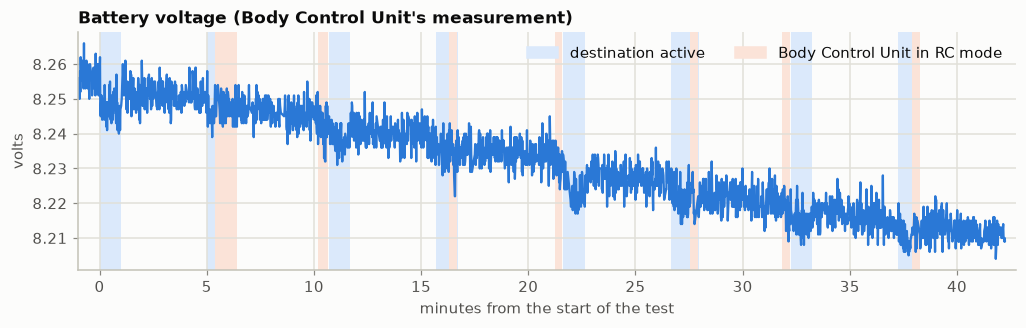

battery: 8.257 V at the start, 8.209 V at the end (48 mV down)
mean while the boat was told to drive: 8.228 V; while idle: 8.231 V (difference 3 mV)


,runs,errors,skipped (since boot),"longest run, ms (since boot)"
bcu_status,2596,0,0,204
compass,25960,0,2,31
control,51920,0,7,3
gps,25960,0,2,19
mqtt,2596,0,0,15
report,2596,0,0,7


In [8]:
fig, ax = plt.subplots(figsize=(11, 2.8))
shade(ax)
ax.plot(pico["min"], pico["bcu.battery_mv"] / 1000, color=BLUE, lw=1.5)
ax.set_ylabel("volts")
ax.set_title("Battery voltage (Body Control Unit's measurement)")
ax.legend(handles=BAND_KEYS, loc="upper right", ncol=2)
time_axis(ax)
plt.show()

nav_v = pico.loc[pico.navigating & (pico["mode"] == "autonomous"), "bcu.battery_mv"].mean()
idle_v = pico.loc[~pico.navigating & (pico["mode"] == "autonomous"), "bcu.battery_mv"].mean()
print("battery: %.3f V at the start, %.3f V at the end (%.0f mV down)" % (
    pico["bcu.battery_mv"].iloc[0] / 1000, pico["bcu.battery_mv"].iloc[-1] / 1000,
    pico["bcu.battery_mv"].iloc[0] - pico["bcu.battery_mv"].iloc[-1]))
print("mean while the boat was told to drive: %.3f V; while idle: %.3f V (difference %.0f mV)" % (nav_v / 1000, idle_v / 1000, idle_v - nav_v))
pd.DataFrame({n: {"runs": last["tasks.%s.runs" % n] - first["tasks.%s.runs" % n],
                  "errors": last["tasks.%s.errors" % n], "skipped (since boot)": last["tasks.%s.skipped" % n],
                  "longest run, ms (since boot)": last["tasks.%s.max_ms" % n]} for n in task_names}).T

**What this shows.**

- **No faults that stopped anything.** No restart of either board, no task errors, no I2C bus
  recovery, no compass or GPS recovery, memory flat.
- **The I2C link to the Body Control Unit is not clean.** About 6 % of the once-a-second status reads fail their
  checksum, and the Body Control Unit rejects roughly 0.7 % of the commands it is sent. Both are caught by the
  checksums and nothing downstream noticed: the Body Control Unit always had a fresh command and never went to
  failsafe. But each rejected command is one the Body Control Unit did not act on, and each failed status read is
  a telemetry message without Body Control Unit data (which is why some charts below have small holes).
- **The errors come in regular bursts, not at random.** The running totals are staircases: status
  reads fail for a few seconds in a row about every 90 seconds, and commands are rejected in a burst
  about every 45 seconds. Electrical noise would not keep time like that. Two boards each running
  their own fixed-rate loop, drifting slowly past each other, would: the pattern fits one board
  reading or writing the shared registers while the other is half-way through updating them. That
  is a guess from the timing, not something this data proves, and it would be a firmware fix
  rather than a wiring one.
- **The battery barely notices the runs.** It falls about 50 mV over the test. The chart shows a dip
  of a few millivolts in each run, clearest in runs 1 and 5 (the two at 40 % throttle). The
  propeller was spinning, so this is simply what the motor draws with no water to push: the test
  says nothing about battery behaviour under real load.

**Where the eye helps.** The staircase is the finding. A table gives the totals and a rate; only the
chart shows that the errors keep a rhythm, which changes what kind of fault to look for.

> **Operator:** the propeller did spin during the runs; from the outside all looked fine.

## 5. RC takeover (objective 2)

Seven switches to RC: four takeovers during a run, while the boat was commanding throttle and
rudder, and three RC tests with the boat idle. For each one: how long from the prompt until the
Body Control Unit reported RC mode, and whether the servo outputs then followed the transmitter.

In [9]:
rows = []
requests = ev[ev.event.isin(["takeover_requested", "rc_test_requested"])]
for r in requests.itertuples():
    kind = "takeover (during a run)" if r.event == "takeover_requested" else "RC test (boat idle)"
    window = rc_windows[rc_windows.start_min >= r.min - 0.02].iloc[0]
    w = tel[(tel["min"] >= window.start_min) & (tel["min"] <= window.end_min) & tel.pico_ok & (tel["mode"] == "rc")]
    rows.append({
        "what": kind,
        "prompt at (min)": round(r.min, 2),
        "Body Control Unit in RC after (s)": round((window.start_min - r.min) * 60, 0),
        "time on RC (s)": round((window.end_min - window.start_min) * 60, 0),
        "throttle stick (µs)": "%d to %d" % (w["bcu.rc_throttle_us"].min(), w["bcu.rc_throttle_us"].max()),
        "rudder stick (µs)": "%d to %d" % (w["bcu.rc_rudder_us"].min(), w["bcu.rc_rudder_us"].max()),
        "output off the stick by, at most (µs)": int(max((w["bcu.out_throttle_us"] - w["bcu.rc_throttle_us"]).abs().max(),
                                                       (w["bcu.out_rudder_us"] - w["bcu.rc_rudder_us"]).abs().max())),
        "boat's own command at the time": "throttle %d %%, rudder %d %%" % (w["output.throttle"].iloc[0], w["output.rudder"].iloc[0]),
    })
interventions = pd.DataFrame(rows, index=pd.RangeIndex(1, len(rows) + 1, name="#"))

auto = tel[tel.pico_ok & (tel["mode"] == "autonomous") & (tel["min"] >= 0)]
auto_off = max((auto["bcu.out_throttle_us"] - auto.cmd_throttle_us).abs().max(), (auto["bcu.out_rudder_us"] - auto.cmd_rudder_us).abs().max())
print("in autonomous mode (%d samples): output off the boat's command by, at most, %d µs" % (len(auto), auto_off))
print("Body Control Unit in failsafe during the test: %d samples; without a fresh command: %d samples" % (
    (in_test["bcu.failsafe"] == True).sum(), (in_test["bcu.cmd_fresh"] == False).sum()))
interventions

in autonomous mode (2200 samples): output off the boat's command by, at most, 0 µs
Body Control Unit in failsafe during the test: 0 samples; without a fresh command: 0 samples


,what,prompt at (min),Body Control Unit in RC after (s),time on RC (s),throttle stick (µs),rudder stick (µs),"output off the stick by, at most (µs)",boat's own command at the time
#,,,,,,,,
1,takeover (during a run),5.26,7.0,62.0,1499 to 1503,1017 to 1947,0,"throttle 20 %, rudder 100 %"
2,RC test (boat idle),10.01,11.0,28.0,1243 to 1992,1500 to 1846,0,"throttle 0 %, rudder 0 %"
3,takeover (during a run),16.19,7.0,21.0,1177 to 1890,1211 to 1587,0,"throttle 20 %, rudder -100 %"
4,RC test (boat idle),20.69,32.0,21.0,1261 to 1716,1525 to 1890,0,"throttle 0 %, rudder 0 %"
5,takeover (during a run),27.39,9.0,23.0,1158 to 1996,1338 to 1681,0,"throttle 21 %, rudder 95 %"
6,RC test (boat idle),31.64,13.0,21.0,1000 to 1900,1308 to 1587,0,"throttle 0 %, rudder 0 %"
7,takeover (during a run),37.59,20.0,21.0,1191 to 1682,1188 to 1776,0,"throttle 20 %, rudder -100 %"


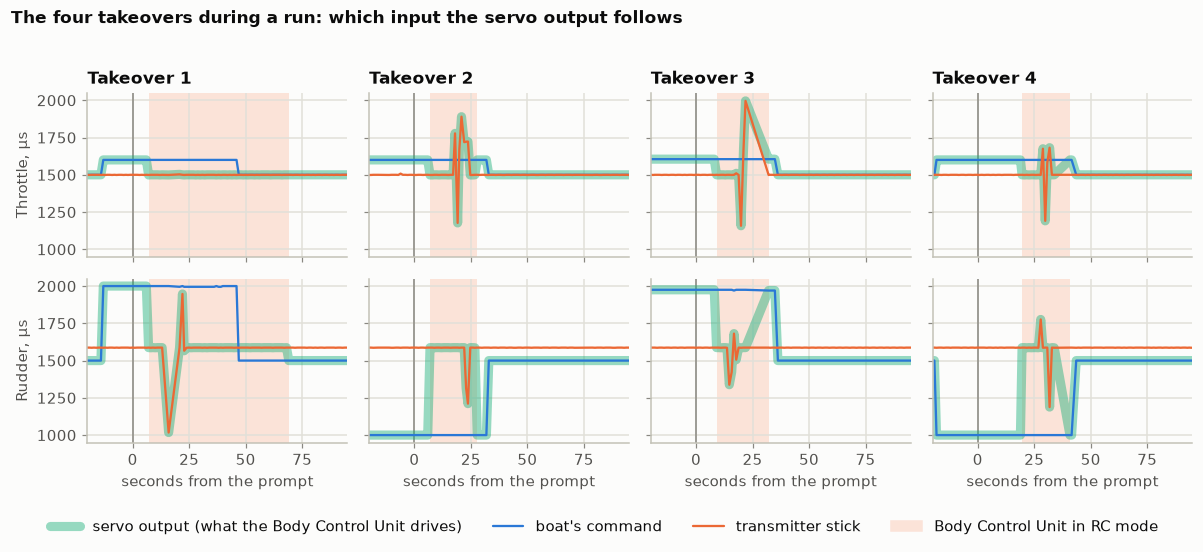

In [10]:
takeovers = ev[ev.event == "takeover_requested"]
fig, axes = plt.subplots(2, len(takeovers), figsize=(11, 4.8), sharex=True, sharey=True)
for col, r in enumerate(takeovers.itertuples()):
    w = tel[(tel["min"] >= r.min - 0.35) & (tel["min"] <= r.min + 1.6) & tel.pico_ok]
    seconds = (w["min"] - r.min) * 60
    for row, (out, stick, command, name) in enumerate((
            ("bcu.out_throttle_us", "bcu.rc_throttle_us", "cmd_throttle_us", "Throttle"),
            ("bcu.out_rudder_us", "bcu.rc_rudder_us", "cmd_rudder_us", "Rudder"))):
        ax = axes[row, col]
        for win in rc_windows.itertuples():
            ax.axvspan((win.start_min - r.min) * 60, (win.end_min - r.min) * 60, color=RC_WASH, lw=0, zorder=0)
        ax.axvline(0, color=MUTED, lw=1)
        ax.plot(seconds, w[out], color=AQUA, lw=6, alpha=0.45, solid_capstyle="butt")
        ax.plot(seconds, w[command], color=BLUE, lw=1.5)
        ax.plot(seconds, w[stick], color=ORANGE, lw=1.5)
        ax.set_xlim(-20, 95)
        ax.set_ylim(950, 2050)
        if row == 0:
            ax.set_title("Takeover %d" % (col + 1))
        else:
            ax.set_xlabel("seconds from the prompt")
        if col == 0:
            ax.set_ylabel("%s, µs" % name)
fig.legend(handles=[plt.Line2D([], [], color=AQUA, lw=6, alpha=0.45, label="servo output (what the Body Control Unit drives)"),
                    plt.Line2D([], [], color=BLUE, lw=1.5, label="boat's command"),
                    plt.Line2D([], [], color=ORANGE, lw=1.5, label="transmitter stick"),
                    Patch(color=RC_WASH, label="Body Control Unit in RC mode")],
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("The four takeovers during a run: which input the servo output follows", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

**What this shows.** In every one of the seven switches the Body Control Unit went to RC and the outputs matched
the transmitter exactly, including the four made while the boat was commanding 20 % throttle and
full rudder. In autonomous mode the outputs matched the boat's command exactly. The Body Control Unit never went
to failsafe and never lacked a fresh command.

The delay from prompt to RC mode is the operator's reaction time plus up to a second of telemetry
resolution, so it measures the procedure, not the electronics. The switch itself is not timed more
finely than once a second by this data.

**Where the eye helps.** In the small charts the thick band (servo output) lies on the blue line
until the shaded region starts and on the orange line inside it. A break in that pattern would be a
takeover that did not take, and it would be obvious at a glance in a way a maximum-difference number
is not. Two things stand out by eye:

- **Takeover 1**: the shaded region runs well past the end of the run, and the throttle stick never
  moves.
- **Takeover 4**: the shaded region starts about 20 seconds after the prompt.

> **Operator:**
> - Takeover 1 (left on RC past the stop, throttle untouched): not intended, operator's mistake.
> - Takeover 4 (20 s to switch): also the operator.
> - The servo and motor did respond to the sticks whenever they were moved.

So both oddities are procedure, not electronics, and the physical response is confirmed by eye.

## 6. GPS (objective 4)

The boat stood in one place for the whole test. The operator handled it twice (marked on the charts):
around minute 14 to reposition the access point, and near the end of run 7 to rotate it by hand and
watch the rudder react. Neither moved it anywhere, so everything the GPS reports as movement is its
own error. That makes this a direct measurement of how far the position wanders, and of how much
speed it invents at standstill.

> **Note: the boat was indoors for this test** (operator's clarification). That changes how to read
> everything in this section. Indoors the satellite signals arrive weakened and reflected off the
> building, so slow wander of several metres is what a GPS receiver normally does there. The
> numbers below describe GPS behaviour in that room, not what to expect on open water.
>
> For comparison, mission 2 measured the same module outdoors: 95 % of fixes within 1.7 m on dry
> land and within about 0.5 m afloat, with a slow drift of 2–3 m over four minutes. Here it is 95 %
> within 6 m and up to 10 m.
>
> What still carries over:
> - **The receiver's quality figures did not show it.** Indoors it still reported 10 or more
>   satellites and an HDOP around 1, the same as outdoors in mission 2. Those figures cannot be
>   used to tell a good fix from a poor one.
> - **The navigation logic met realistic bad input.** How the arrival radius and the "still moving"
>   check behave on these fixes is a fair preview of a bad-reception day, even if the size of the
>   error is pessimistic.

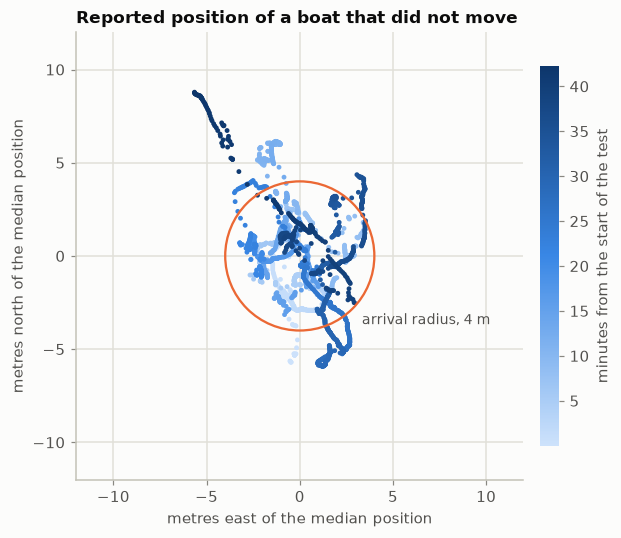

In [11]:
g = in_test
centre_e, centre_n = g.east_m.median(), g.north_m.median()
radius = np.hypot(g.east_m - centre_e, g.north_m - centre_n)
speed = g["gps.sog_kn"] * KN_TO_M_S

fig, ax = plt.subplots(figsize=(6.4, 6.4))
points = ax.scatter(g.east_m - centre_e, g.north_m - centre_n, c=g["min"], cmap=TIME_RAMP, s=10, linewidths=0)
ax.add_patch(Circle((0, 0), ARRIVAL_RADIUS_M, fill=False, color=ORANGE, lw=1.5))
ax.annotate("arrival radius, %d m" % ARRIVAL_RADIUS_M, (ARRIVAL_RADIUS_M * 0.71, -ARRIVAL_RADIUS_M * 0.71), xytext=(6, -10),
            textcoords="offset points", color=INK_2, fontsize=9)
limit = math.ceil(max(radius.max(), ARRIVAL_RADIUS_M) + 1)
ax.set_xlim(-limit, limit)
ax.set_ylim(-limit, limit)
ax.set_aspect("equal")
ax.set_xlabel("metres east of the median position")
ax.set_ylabel("metres north of the median position")
ax.set_title("Reported position of a boat that did not move")
bar = fig.colorbar(points, ax=ax, shrink=0.7, pad=0.03)
bar.set_label("minutes from the start of the test")
bar.outline.set_visible(False)
plt.show()

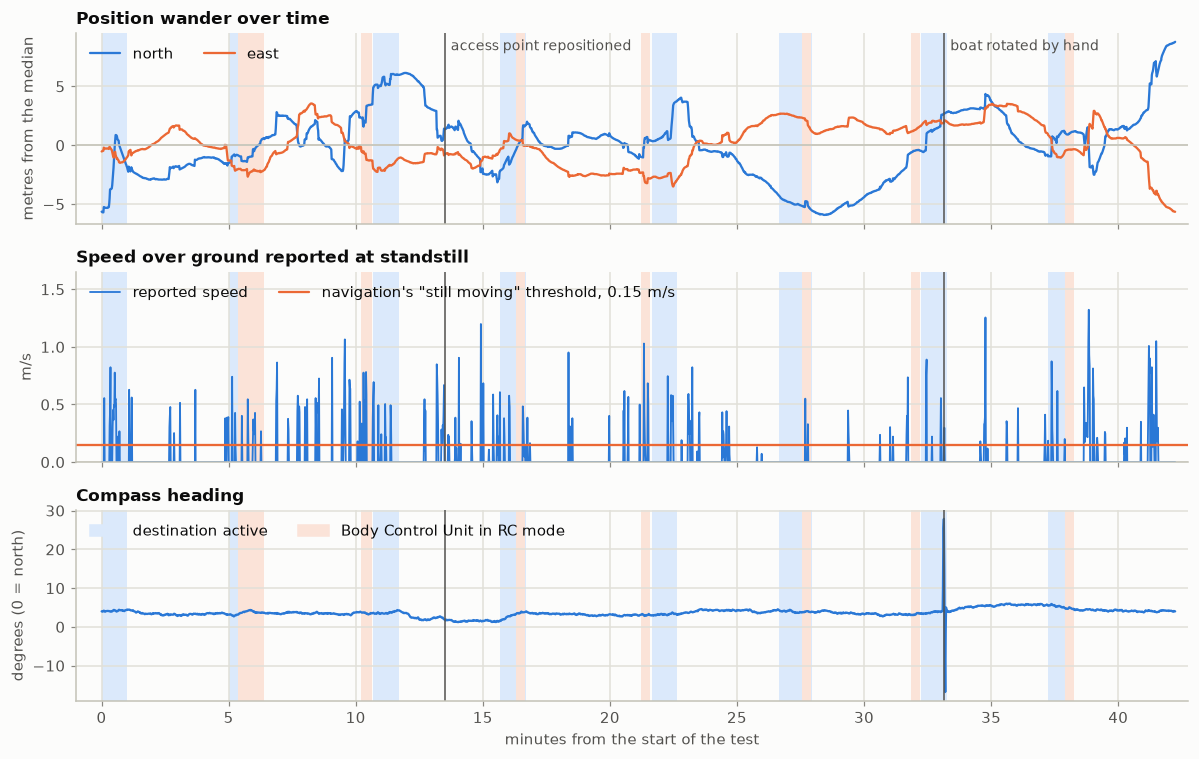

,GPS
fixes,2535
fix lost or not 'good' (messages),0
"satellites, min / median / max",10 / 13 / 15
"HDOP, median / worst",0.9 / 1.2
distance from the median position: median (m),2.6
… 95 % of fixes within (m),6.0
… farthest (m),10.4
fixes outside the 4 m arrival radius (%),22.1
north span / east span (m),14.7 / 9.2
largest jump between two fixes (m),1.6


In [12]:
fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
ax = axes[0]
shade(ax)
ax.plot(g["min"], g.north_m - centre_n, color=BLUE, lw=1.5, label="north")
ax.plot(g["min"], g.east_m - centre_e, color=ORANGE, lw=1.5, label="east")
ax.axhline(0, color=AXIS, lw=1)
ax.set_ylabel("metres from the median")
ax.set_title("Position wander over time")
mark_operator(ax)
ax.legend(loc="upper left", ncol=2)

ax = axes[1]
shade(ax)
ax.plot(g["min"], speed, color=BLUE, lw=1.2)
ax.axhline(STILL_MOVING_M_S, color=ORANGE, lw=1.5)
ax.set_ylim(0, speed.max() * 1.25)
ax.legend(handles=[plt.Line2D([], [], color=BLUE, lw=1.2, label="reported speed"),
                   plt.Line2D([], [], color=ORANGE, lw=1.5, label="navigation's \"still moving\" threshold, %.2f m/s" % STILL_MOVING_M_S)],
          loc="upper left", ncol=2)
ax.set_ylabel("m/s")
ax.set_title("Speed over ground reported at standstill")
mark_operator(ax, labels=False)

ax = axes[2]
shade(ax)
heading = g["compass.heading"].where(g["compass.heading"] < 180, g["compass.heading"] - 360)
off_heading = (heading - heading.median()).abs() > 10
ax.plot(g["min"], heading, color=BLUE, lw=1.5)
mark_operator(ax, labels=False)
ax.set_ylabel("degrees (0 = north)")
ax.set_title("Compass heading")
ax.legend(handles=BAND_KEYS, loc="upper left", ncol=2)
time_axis(ax)
fig.tight_layout()
plt.show()

step = np.hypot(g.east_m.diff(), g.north_m.diff())
pd.Series({
    "fixes": len(g),
    "fix lost or not 'good' (messages)": int((~g["gps.fix_valid"].astype(bool) | ~g["gps.fix_good"].astype(bool)).sum()),
    "satellites, min / median / max": "%d / %d / %d" % (g["gps.sats"].min(), g["gps.sats"].median(), g["gps.sats"].max()),
    "HDOP, median / worst": "%.1f / %.1f" % (g["gps.hdop"].median(), g["gps.hdop"].max()),
    "distance from the median position: median (m)": round(radius.median(), 1),
    "… 95 % of fixes within (m)": round(radius.quantile(0.95), 1),
    "… farthest (m)": round(radius.max(), 1),
    "fixes outside the %d m arrival radius (%%)" % ARRIVAL_RADIUS_M: round(100 * (radius > ARRIVAL_RADIUS_M).mean(), 1),
    "north span / east span (m)": "%.1f / %.1f" % (g.north_m.max() - g.north_m.min(), g.east_m.max() - g.east_m.min()),
    "largest jump between two fixes (m)": round(step.max(), 1),
    "reported speed at standstill: median / 95 % / max (m/s)": "%.2f / %.2f / %.2f" % (speed.median(), speed.quantile(0.95), speed.max()),
    "time the reported speed was over the %.2f m/s threshold (%%)" % STILL_MOVING_M_S: round(100 * (speed > STILL_MOVING_M_S).mean(), 1),
    "altitude span (m)": round(g["gps.alt_m"].max() - g["gps.alt_m"].min(), 1),
    "compass heading: median, and the range 98 % of readings are in (degrees)": "%.1f, %.1f to %.1f" % (heading.median(), heading.quantile(0.01), heading.quantile(0.99)),
    "compass readings more than 10 degrees off the median": "%d, at minute %s" % (off_heading.sum(), ", ".join(sorted({"%.1f" % m for m in g["min"][off_heading]}))),
}, name="GPS").to_frame()

**What this shows.**

- **No bad fixes in the usual sense**: a valid, "good" fix for the whole test, 10 or more
  satellites, a low HDOP throughout, no jump between consecutive fixes larger than a couple of metres.
- **But the position wanders slowly by more than the arrival radius.** With the boat standing
  still, the reported position drifts several metres over minutes, mostly north–south. A good share
  of the fixes are outside a 4 m circle around the median. A boat holding position on these fixes
  would see itself leave and re-enter the arrival radius without moving.
- **The GPS reports speed at standstill**, often above the 0.15 m/s that the navigation code treats
  as "still moving", with peaks over 1 m/s.

For the question in the mission plan (does navigation need more robustness against GPS error?),
this test gives a qualified yes. The arrival radius needs hysteresis and the "still moving" check in
`_stop()` cannot rely on this threshold; both are already open items in `gnc.py`, and both follow
from mission 2's outdoor drift of 2–3 m as well. But the size of the error seen here is an indoor
figure, so it should not be used to choose the radius. Mission 2's outdoor numbers are the better
basis for that.

**Where the eye helps.** The scatter coloured by time is the important picture: the fixes are not a
round cloud of independent errors but a slow trail, so averaging a few seconds of fixes would not
remove the error. The time series shows the same thing as slow swings instead of noise around zero.

- **The drift at the end has no specific cause.** In the last two minutes the position runs off
  about 10 m to the north-west and stays there, with 10 or more satellites and a low HDOP the whole
  time. Nothing around the boat changed. Indoors, a shift like this as satellites move is not
  surprising; the point that stands is that the receiver's own quality figures gave no warning.
- **The compass was steady.** Apart from the hand rotation it stays within a few degrees. It shifts
  by about 2° between minutes 12 and 16, around the time the access point was handled.

One thing still worth ruling out, outdoors: the access point sits on the boat, close to the GPS
antenna, and a transmitter next to a GPS antenna is a known cause of degraded fixes. Being indoors
is enough to explain what is seen here, so this test cannot tell whether the access point
contributes. Mission 2 logged over USB, and its page does not say whether an access point was on
board, so that comparison does not settle it either.

> **Operator:** the boat was indoors. Two interactions with the boat: the access point was checked and repositioned around
> minute 14, and the boat was rotated during the south run to check the compass and rudder. The
> drift at the end came as a surprise; nothing changed around the boat.

## 7. Commands and what the boat did with them (plan step 2)

Each destination and each stop was confirmed from the boat's own telemetry. The destinations were
50 m north, east, south and west of the start position, twice round.

In [13]:
confirm = ev[ev.event == "destination_confirmed"].set_index("number")["after_s"]
stop_confirm = ev[ev.event == "stop_confirmed"].set_index("number")["after_s"]
table = runs[["section", "direction", "takeover"]].copy()
table["start (min)"] = runs.start_min.round(2)
table["destination taken after (s)"] = confirm
table["stop taken after (s)"] = stop_confirm
for n, r in runs.iterrows():
    w = tel[(tel["min"] > r.start_min) & (tel["min"] <= r.stop_min) & tel.navigating]
    error = w["nav.course_error_deg"]
    table.loc[n, "distance seen (m)"] = "%.0f to %.0f" % (w["nav.distance_m"].min(), w["nav.distance_m"].max())
    table.loc[n, "course error (°)"] = "%.0f to %.0f" % (error.min(), error.max())
    table.loc[n, "throttle (%)"] = "%d to %d" % (w["output.throttle"].min(), w["output.throttle"].max())
    table.loc[n, "rudder (%)"] = "%d to %d" % (w["output.rudder"].min(), w["output.rudder"].max())
    table.loc[n, "rudder reversals"] = "%d" % (np.sign(w["output.rudder"]).diff().abs() == 2).sum()
print("not confirmed: %d destinations, %d stops; commands the boat rejected: %d" % (
    (ev.event == "destination_not_confirmed").sum(), (ev.event == "stop_not_confirmed").sum(),
    tel.bad_commands.iloc[-1] - tel.bad_commands.iloc[0]))
table

not confirmed: 0 destinations, 0 stops; commands the boat rejected: 0


,section,direction,takeover,start (min),destination taken after (s),stop taken after (s),distance seen (m),course error (°),throttle (%),rudder (%),rudder reversals
run,,,,,,,,,,,
1,1,north,False,0.01,0.8,0.9,45 to 51,-4 to -3,39 to 39,-5 to -3,0
2,1,east,True,5.01,0.9,0.9,51 to 52,89 to 91,20 to 20,99 to 100,0
3,2,south,False,10.69,0.8,0.8,59 to 61,174 to 175,20 to 20,100 to 100,0
4,2,west,True,15.69,0.6,0.9,50 to 52,-101 to -94,20 to 20,-100 to -100,0
5,3,north,False,21.64,1.1,0.7,42 to 45,-1 to 1,40 to 40,-1 to 1,0
6,3,east,True,26.64,0.8,0.9,47 to 48,85 to 86,21 to 21,94 to 95,0
7,4,south,False,32.25,2.0,0.9,54 to 57,-175 to 179,20 to 20,-100 to 100,2
8,4,west,True,37.25,1.8,0.6,50 to 51,-102 to -99,20 to 20,-100 to -100,0


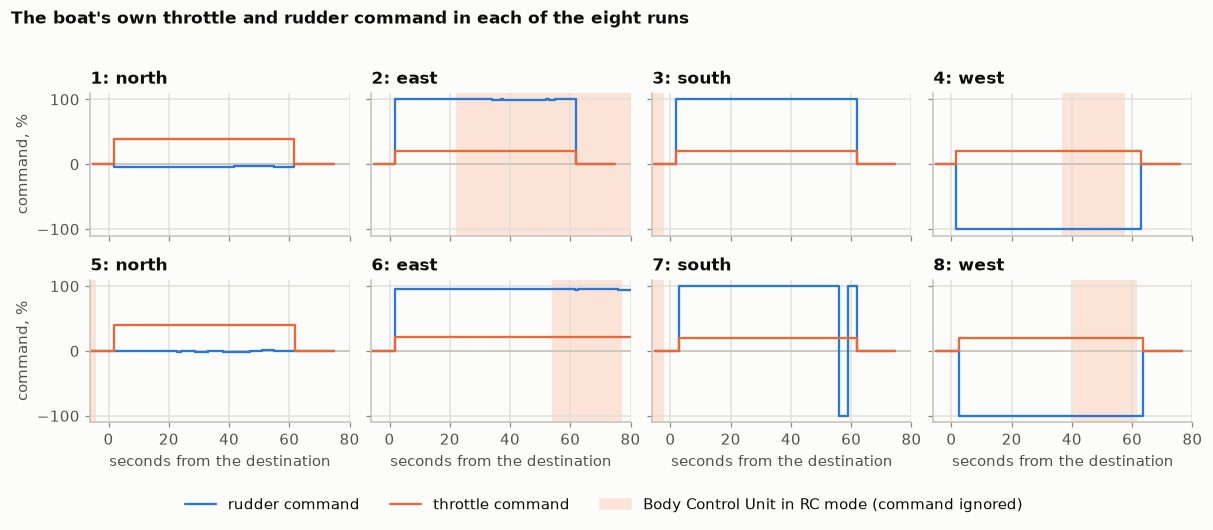

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharex=True, sharey=True)
for ax, (n, r) in zip(axes.flat, runs.iterrows()):
    w = tel[(tel["min"] >= r.start_min - 0.1) & (tel["min"] <= r.stop_min + 0.25)]
    seconds = (w["min"] - r.start_min) * 60
    for win in rc_windows.itertuples():
        ax.axvspan((win.start_min - r.start_min) * 60, (win.end_min - r.start_min) * 60, color=RC_WASH, lw=0, zorder=0)
    ax.axhline(0, color=AXIS, lw=1)
    ax.plot(seconds, w["output.rudder"], color=BLUE, lw=1.5, drawstyle="steps-post")
    ax.plot(seconds, w["output.throttle"], color=ORANGE, lw=1.5, drawstyle="steps-post")
    ax.set_xlim(-6, 80)
    ax.set_ylim(-110, 110)
    ax.set_title("%d: %s" % (n, r.direction))
for ax in axes[1]:
    ax.set_xlabel("seconds from the destination")
for ax in axes[:, 0]:
    ax.set_ylabel("command, %")
fig.legend(handles=[plt.Line2D([], [], color=BLUE, lw=1.5, label="rudder command"),
                    plt.Line2D([], [], color=ORANGE, lw=1.5, label="throttle command"),
                    Patch(color=RC_WASH, label="Body Control Unit in RC mode (command ignored)")],
           loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.04))
fig.suptitle("The boat's own throttle and rudder command in each of the eight runs", x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=(0, 0.04, 1, 0.96))
plt.show()

**What this shows.**

- **Every command was picked up**, within about a second (two at most), and none was rejected.
- **The navigation output is what the code says it should be** for a boat pointing north: straight
  ahead at 40 % for the northern destinations, full right rudder for east, full left for west.
- **Run 7 is the rotation check.** The operator turned the boat by hand. The heading reading went
  from about 4° up to 28°, then down to about 343°, and back. With the destination directly astern,
  the shortest turn is to the right while the heading reads east of north and to the left when it
  reads west of north, and the rudder command followed: full right, full left, full right again.
  The operator saw the rudder react as expected. That is the first check of the heading-to-rudder
  chain with real motion. (Which way the boat was physically turned first is not recorded, so this
  does not by itself confirm the compass direction or the rudder direction: see the follow-up
  questions.)
- **It also shows a knife edge.** For a target near dead astern the command goes from one stop to
  the other as the heading crosses the reciprocal bearing. That is correct, but with heading or
  position noise right at that point the rudder would slam back and forth. Run 3, the same
  destination with the boat left alone, stayed on one side throughout.
- **The distance the boat saw** to a destination 50 m away ranges from about 42 to 61 m, which is
  the GPS wander from section 6 again.

**Where the eye helps.** The rudder reversal at the end of run 7 is plain in the small chart and
easy to miss in a table of minimum and maximum.

> **Operator:** the boat was physically rotated to see the rudder react. It behaved as expected.

## 8. Summary

The table is computed from this run's data; the reading of it is underneath.

In [15]:
verdicts = pd.DataFrame([
    ("1. Electronics fault-free",
     "PASS, with a finding" if uptime_ok and last["tasks.control.errors"] == 0 and last.i2c_recoveries == first.i2c_recoveries else "CHECK",
     "no restarts, task errors or recoveries; %.1f %% of Body Control Unit status reads and %.2f %% of commands fail their checksum" % (
         100 * status_bad.sum() / len(tel), 100 * pico_cmd_errors.sum() / commands_sent)),
    ("2. RC takeover at any time",
     "PASS" if interventions["output off the stick by, at most (µs)"].max() <= 5 and len(interventions) == 7 else "CHECK",
     "%d of %d switches to RC took effect, %d of them during a run; outputs matched the sticks to within %d µs" % (
         len(interventions), len(requests), (interventions.what.str.startswith("takeover")).sum(),
         interventions["output off the stick by, at most (µs)"].max())),
    ("3. Telemetry without gaps", "PASS" if lost == 0 and (gap > 5).sum() == 0 else "CHECK",
     "%d of %d messages received, longest wait %.1f s" % (len(tel), tel.seq.iloc[-1] - tel.seq.iloc[0] + 1, gap.max())),
    ("4. GPS without large inaccuracies", "NOT ANSWERED (indoors)",
     "fix reported good throughout, but the boat was indoors: position wanders up to %.0f m and %.0f %% of fixes fall outside the %d m arrival radius" % (
         radius.max(), 100 * (radius > ARRIVAL_RADIUS_M).mean(), ARRIVAL_RADIUS_M)),
    ("5. Access point stays up",
     "PASS" if link_last["link.wifi_connects"] == link_first["link.wifi_connects"] and link_last["link.errors"] == link_first["link.errors"] else "CHECK",
     "%d WiFi connect, %d broker connect, %d link errors; signal %d to %d dBm (the access point is on the boat)" % (
         link_last["link.wifi_connects"], link_last["link.mqtt_connects"], link_last["link.errors"], tel["link.rssi"].min(), tel["link.rssi"].max())),
    ("Plan: destinations picked up", "PASS" if (ev.event == "destination_not_confirmed").sum() == 0 else "CHECK",
     "%d of %d destinations and %d of %d stops confirmed, slowest %.1f s" % (
         len(confirm), len(runs), len(stop_confirm), len(runs), max(confirm.max(), stop_confirm.max()))),
], columns=["objective", "verdict", "evidence"]).set_index("objective")
with pd.option_context("display.max_colwidth", None):
    display(verdicts)

,verdict,evidence
objective,,
1. Electronics fault-free,"PASS, with a finding","no restarts, task errors or recoveries; 6.3 % of Body Control Unit status reads and 0.70 % of commands fail their checksum"
2. RC takeover at any time,PASS,"7 of 7 switches to RC took effect, 4 of them during a run; outputs matched the sticks to within 0 µs"
3. Telemetry without gaps,PASS,"2597 of 2597 messages received, longest wait 2.2 s"
4. GPS without large inaccuracies,NOT ANSWERED (indoors),"fix reported good throughout, but the boat was indoors: position wanders up to 10 m and 22 % of fixes fall outside the 4 m arrival radius"
5. Access point stays up,PASS,"1 WiFi connect, 1 broker connect, 0 link errors; signal -40 to -26 dBm (the access point is on the boat)"
Plan: destinations picked up,PASS,"8 of 8 destinations and 8 of 8 stops confirmed, slowest 2.0 s"


### Reading

The control chain works: commands arrive, the Body Control Unit executes them exactly, the operator can take over
during a run and gets exact control, and telemetry is complete. Nothing restarted or needed recovery.
The operator confirmed what the data cannot show: the propeller spun, and the servo and motor
followed the sticks.

Three things came out of the test that matter before going on the water:

1. **The GPS objective is not answered by this test, because the boat was indoors.** The wander seen
   here (up to 10 m) is an indoor figure; mission 2's outdoor measurements are the reference for
   open water. Two things do carry over: the receiver reported a good fix throughout, so its
   quality figures cannot be trusted to flag a poor one, and the navigation's stop and "still
   moving" logic needs hysteresis either way.
2. **The I2C link to the Body Control Unit loses data in regular bursts.** Harmless here because both directions
   are checked and repeated, but the rhythm suggests a timing clash between the two boards that
   could be fixed in firmware.
3. **A destination near dead astern puts the rudder on a knife edge.** The hand rotation in run 7
   showed the rudder reacting correctly, and also that it goes from stop to stop as the heading
   crosses the reciprocal bearing.

The two oddities in the takeovers (the switch left on RC after takeover 1, the slow switch in
takeover 4) were the operator's, not the system's.

### What this test did not cover

- **The access point's internet connection away from this spot.** The WiFi hop is on board and does
  not change with distance; the access point's own uplink does, and it is not measured.
- **Recovery.** Nothing failed, so reconnecting after a WiFi or broker dropout was not exercised.
- **Load.** The propeller ran in air, so battery and motor behaviour under load are untested.
- **GPS accuracy outdoors.** The boat was indoors, so the position error measured here does not
  represent open water. That includes any effect of the on-board access point on the GPS.
- **Motion.** Apart from one hand rotation the boat stood still, so compass and GPS were not tested
  against each other.
- **Fine timing of the takeover.** Telemetry is once a second.

### Follow-up questions for the operator

The first round of questions is answered (comments at the end). Three things would still help:

1. **What connects the on-board access point to the internet** (a phone, a cellular modem)? That
   link is now the one whose range matters, and it decides what to measure next.
2. **When the access point was repositioned (around minute 14), where did it end up relative to the
   compass and the GPS antenna?** The heading shifts by about 2° between minutes 12 and 16, which
   could be the boat being nudged or the access point's position affecting the compass.
3. **During the hand rotation, which way did the rudder physically move** when the bow was turned
   to the right of north? "As expected" is recorded; the direction itself would close the question
   of the rudder sign, which until now was unverified.


# Operator's comments

1) Yes, RC checks were short
2) Access point is integrated within the UAV
3) Yes, on outside all looked fine
4) Not intended, but the operator's fault
5) Also operator's fault
6) Yes, when were controlled to
7) Two interactions: The access point was checked/reposition around minute 14; and, compass/rotation was checked during the south run
8) No, that came as a surprise
9) Yes, boat was physically rotated, to see the rudder reaction. Behaved as expected.
